# Task 5 — Time Series Preprocessing & Forecasting

## 1. Project Overview

This project focuses on preparing historical weather data and building time series forecasting models using statistical methods.

The workflow includes data preprocessing, missing value handling, outlier treatment, feature engineering, stationarity testing, ARIMA/SARIMA modeling, residual diagnostics, forecasting, and model evaluation.

## 2. Project Objective

The main objective is to build and evaluate a time series model to forecast daily average temperature using historical weather observations.

## 3. Dataset Description

The dataset contains daily weather observations for Cairo from 2016 to 2025.

The available weather parameters are:

* `T2M`: Daily average temperature.
* `T2M_MAX`: Daily maximum temperature.
* `T2M_MIN`: Daily minimum temperature.
* `PRECTOTCORR`: Corrected precipitation.
* `WS10M`: Wind speed at 10 meters.
* `RH2M`: Relative humidity at 2 meters.

## 4. Target Variable

The target variable is `T2M`, representing the daily average temperature in degrees Celsius.

## 5. Modeling Approach

The project will investigate ARIMA and SARIMA models for time series forecasting.

Model performance will be evaluated using chronological train/test splitting, forecasting metrics, residual diagnostics, and walk-forward validation.

## 6. Expected Outcome

The expected outcome is a complete time series forecasting workflow that prepares historical weather data, evaluates forecasting models, and generates temperature forecasts with confidence intervals.


## 2. Importing Libraries

The libraries used in this project support data manipulation, visualization, time series analysis, statistical modeling, and forecasting evaluation.


In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully.")

Libraries imported successfully.


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## 3. Loading the Weather Dataset

The historical weather dataset is loaded from a CSV file into a Pandas DataFrame for time series preprocessing and forecasting.

The dataset contains daily weather observations, including temperature, relative humidity, wind speed, and precipitation.


In [4]:
df = pd.read_csv("/content/drive/MyDrive/cellula_tasks/TASK 4/cairo_weather_prepared.csv")

print("Dataset loaded successfully.")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset Shape: (3653, 12)


,date,T2M_MAX,T2M_MIN,T2M,PRECTOTCORR,WS10M,RH2M,T2M_30D_ROLLING,year,month,is_rainy_day,TEMP_RANGE
0,2016-01-01,13.03,5.53,10.08,0.90,5.49,66.37,NaN,2016,1,True,7.50
1,2016-01-02,14.35,3.52,8.31,0.01,3.08,63.88,NaN,2016,1,True,10.83
2,2016-01-03,18.01,4.84,10.54,0.02,3.97,67.52,NaN,2016,1,True,13.17
3,2016-01-04,19.33,6.47,11.99,0.00,4.22,63.10,NaN,2016,1,False,12.86
4,2016-01-05,20.48,7.56,12.78,0.00,5.43,47.29,NaN,2016,1,False,12.92


## 4. Initial Dataset Inspection

This section examines the dataset structure, column data types, date coverage, and data quality before applying time series preprocessing.

The target variable for forecasting is `T2M`, representing daily average temperature.


In [5]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDate Range:")
print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())

print("\nDuplicate Dates:", df["date"].duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3653 entries, 0 to 3652
Data columns (total 12 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   date             3653 non-null   object 
 1   T2M_MAX          3653 non-null   float64
 2   T2M_MIN          3653 non-null   float64
 3   T2M              3653 non-null   float64
 4   PRECTOTCORR      3653 non-null   float64
 5   WS10M            3653 non-null   float64
 6   RH2M             3653 non-null   float64
 7   T2M_30D_ROLLING  3624 non-null   float64
 8   year             3653 non-null   int64  
 9   month            3653 non-null   int64  
 10  is_rainy_day     3653 non-null   bool   
 11  TEMP_RANGE       3653 non-null   float64
dtypes: bool(1), float64(8), int64(2), object(1)
memory usage: 317.6+ KB

Missing Values:
date                0
T2M_MAX             0
T2M_MIN             0
T2M                 0
PRECTOTCORR         0
WS10M               0
RH2M  

## 5. Date Conversion and Time Ordering

The date column is converted to a datetime data type to support chronological sorting, time-based indexing, and time series analysis.

The dataset is then sorted by date to ensure that observations follow the correct temporal order.


In [6]:
df["date"] = pd.to_datetime(df["date"])

df = df.sort_values("date").reset_index(drop=True)

print("Date Data Type:", df["date"].dtype)

print("\nFirst Date:", df["date"].min())
print("Last Date:", df["date"].max())

print("\nIs Chronologically Sorted:", df["date"].is_monotonic_increasing)

display(df.head())

Date Data Type: datetime64[ns]

First Date: 2016-01-01 00:00:00
Last Date: 2025-12-31 00:00:00

Is Chronologically Sorted: True


,date,T2M_MAX,T2M_MIN,T2M,PRECTOTCORR,WS10M,RH2M,T2M_30D_ROLLING,year,month,is_rainy_day,TEMP_RANGE
0,2016-01-01,13.03,5.53,10.08,0.90,5.49,66.37,NaN,2016,1,True,7.50
1,2016-01-02,14.35,3.52,8.31,0.01,3.08,63.88,NaN,2016,1,True,10.83
2,2016-01-03,18.01,4.84,10.54,0.02,3.97,67.52,NaN,2016,1,True,13.17
3,2016-01-04,19.33,6.47,11.99,0.00,4.22,63.10,NaN,2016,1,False,12.86
4,2016-01-05,20.48,7.56,12.78,0.00,5.43,47.29,NaN,2016,1,False,12.92


## 6. Setting the Date as the Index

The date column is set as the DataFrame index to support time-series operations and make the chronological structure of the dataset explicit.

The dataset contains daily weather observations from January 1, 2016, to December 31, 2025.


In [7]:
df = df.set_index("date")

print("Dataset Index:")
print(df.index)

print("\nIndex Type:", type(df.index))

print("\nIs Chronologically Sorted:", df.index.is_monotonic_increasing)

display(df.head())

Dataset Index:
DatetimeIndex(['2016-01-01', '2016-01-02', '2016-01-03', '2016-01-04',
               '2016-01-05', '2016-01-06', '2016-01-07', '2016-01-08',
               '2016-01-09', '2016-01-10',
               ...
               '2025-12-22', '2025-12-23', '2025-12-24', '2025-12-25',
               '2025-12-26', '2025-12-27', '2025-12-28', '2025-12-29',
               '2025-12-30', '2025-12-31'],
              dtype='datetime64[ns]', name='date', length=3653, freq=None)

Index Type: <class 'pandas.core.indexes.datetimes.DatetimeIndex'>

Is Chronologically Sorted: True


,T2M_MAX,T2M_MIN,T2M,PRECTOTCORR,WS10M,RH2M,T2M_30D_ROLLING,year,month,is_rainy_day,TEMP_RANGE
date,,,,,,,,,,,
2016-01-01,13.03,5.53,10.08,0.90,5.49,66.37,NaN,2016,1,True,7.50
2016-01-02,14.35,3.52,8.31,0.01,3.08,63.88,NaN,2016,1,True,10.83
2016-01-03,18.01,4.84,10.54,0.02,3.97,67.52,NaN,2016,1,True,13.17
2016-01-04,19.33,6.47,11.99,0.00,4.22,63.10,NaN,2016,1,False,12.86
2016-01-05,20.48,7.56,12.78,0.00,5.43,47.29,NaN,2016,1,False,12.92


## 7. Checking for Missing Dates

Although the dataset is chronologically sorted, some calendar dates may still be missing.

This step verifies whether the dataset contains a continuous sequence of daily observations before applying time-series forecasting methods.


In [8]:
# Create the expected daily date range
expected_dates = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="D"
)

# Find dates that are missing from the dataset
missing_dates = expected_dates.difference(df.index)

print("Expected Number of Daily Observations:", len(expected_dates))
print("Actual Number of Observations:", len(df))
print("Number of Missing Dates:", len(missing_dates))

if len(missing_dates) > 0:
    print("\nMissing Dates:")
    print(missing_dates)
else:
    print("\nNo missing dates found.")

Expected Number of Daily Observations: 3653
Actual Number of Observations: 3653
Number of Missing Dates: 0

No missing dates found.


## 8. Setting the Daily Frequency

The dataset is assigned a daily frequency (`D`) because the missing-date check confirmed that every calendar day is represented.

This makes the expected time interval explicit for subsequent time-series analysis and forecasting.


In [9]:
df = df.asfreq("D")

print("Time Series Frequency:", df.index.freq)
print("Dataset Shape:", df.shape)

print("\nMissing Values After Setting Frequency:")
print(df.isnull().sum())

Time Series Frequency: <Day>
Dataset Shape: (3653, 11)

Missing Values After Setting Frequency:
T2M_MAX             0
T2M_MIN             0
T2M                 0
PRECTOTCORR         0
WS10M               0
RH2M                0
T2M_30D_ROLLING    29
year                0
month               0
is_rainy_day        0
TEMP_RANGE          0
dtype: int64


## 9. Target Selection and Time Series Preparation

The target variable for forecasting is `T2M`, which represents the daily average air temperature in degrees Celsius.

A univariate time-series approach is selected for the baseline model. It uses historical temperature observations to learn temporal patterns and forecast future temperatures.

Other weather variables will not be included in this initial baseline model.


In [10]:
# Select the target variable
target = df["T2M"]

print("Target Variable: T2M")
print("Target Description: Daily Average Temperature")
print("Target Shape:", target.shape)

print("\nMissing Values in Target:", target.isnull().sum())

print("\nTarget Statistics:")
display(target.describe())

Target Variable: T2M
Target Description: Daily Average Temperature
Target Shape: (3653,)

Missing Values in Target: 0

Target Statistics:


,T2M
count,3653.000000
mean,22.101204
std,6.994020
min,6.530000
25%,15.650000
50%,22.740000
75%,28.860000
max,35.380000


## 9b. Outlier Treatment

Weather data is seasonal, so a global z-score is not appropriate. We first check physically impossible values, then use a trailing rolling z-score based only on past values to avoid look-ahead leakage. Flagged values are capped rather than deleted, so the series stays continuous for ARIMA.

In [11]:
# 1) Physically impossible values
print("T2M range:", target.min(), "to", target.max())
print("Rows with T2M_MAX < T2M_MIN:", int((df["T2M_MAX"] < df["T2M_MIN"]).sum()))
print("Rows with T2M outside [T2M_MIN, T2M_MAX]:", int(((df["T2M"] < df["T2M_MIN"]) | (df["T2M"] > df["T2M_MAX"])).sum()))
print("Rows with RH2M outside [0, 100]:", int(((df["RH2M"] < 0) | (df["RH2M"] > 100)).sum()))

# 2) Trailing 30-day rolling z-score (past values only)
roll_mean = target.shift(1).rolling(window=30, min_periods=15).mean()
roll_std = target.shift(1).rolling(window=30, min_periods=15).std()
z_scores = (target - roll_mean) / roll_std
outlier_mask = z_scores.abs() > 3
print("Rolling z-score outliers (|z| > 3):", int(outlier_mask.sum()))

# 3) Winsorize flagged values to the rolling bounds
upper = roll_mean + 3 * roll_std
lower = roll_mean - 3 * roll_std
target_clean = target.where(~outlier_mask, target.clip(lower=lower, upper=upper))
print("Values capped:", int(outlier_mask.sum()))

target_raw = target.copy()
target = target_clean.rename("T2M")

T2M range: 6.53 to 35.38
Rows with T2M_MAX < T2M_MIN: 0
Rows with T2M outside [T2M_MIN, T2M_MAX]: 0
Rows with RH2M outside [0, 100]: 0
Rolling z-score outliers (|z| > 3): 79
Values capped: 79


## 10. Visualizing the Temperature Time Series

The daily average temperature series is plotted over the entire observation period to examine its temporal behavior.

The visualization helps identify potential long-term trends, recurring seasonal patterns, and short-term fluctuations before conducting stationarity tests and selecting a forecasting model.


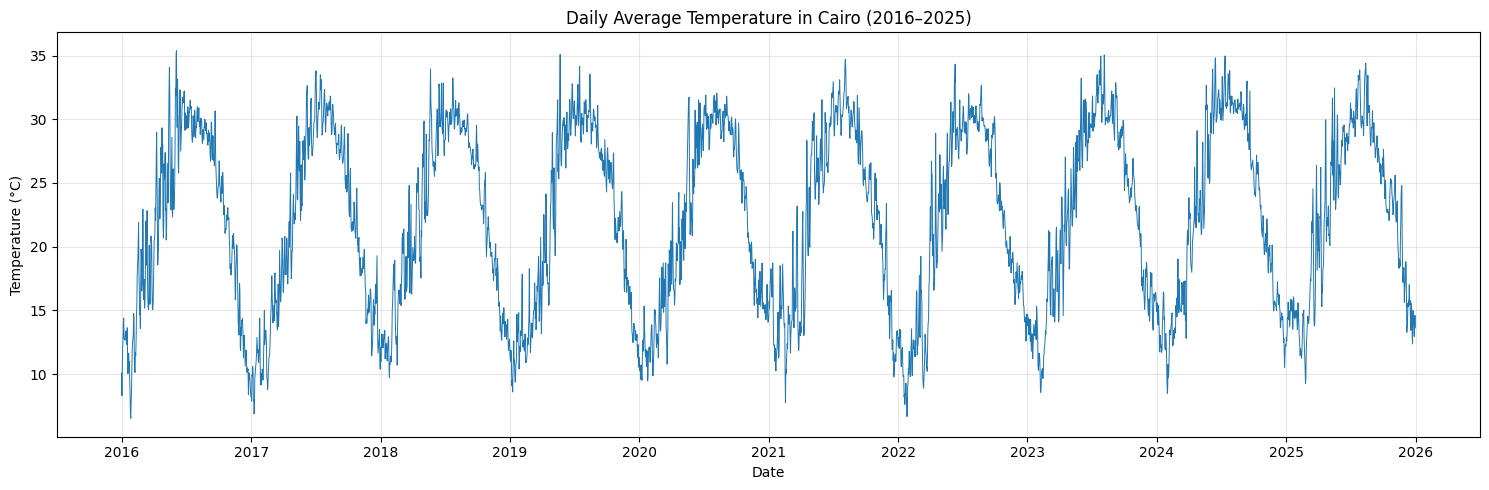

In [12]:
plt.figure(figsize=(15, 5))

plt.plot(target.index, target, linewidth=0.7)

plt.title("Daily Average Temperature in Cairo (2016–2025)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 11. Rolling Mean Analysis

A 30-day rolling mean is calculated and plotted alongside the daily average temperature series.

The rolling mean smooths short-term fluctuations and helps reveal broader changes in temperature over time. It is used for exploratory analysis rather than as an input feature for the baseline forecasting model.


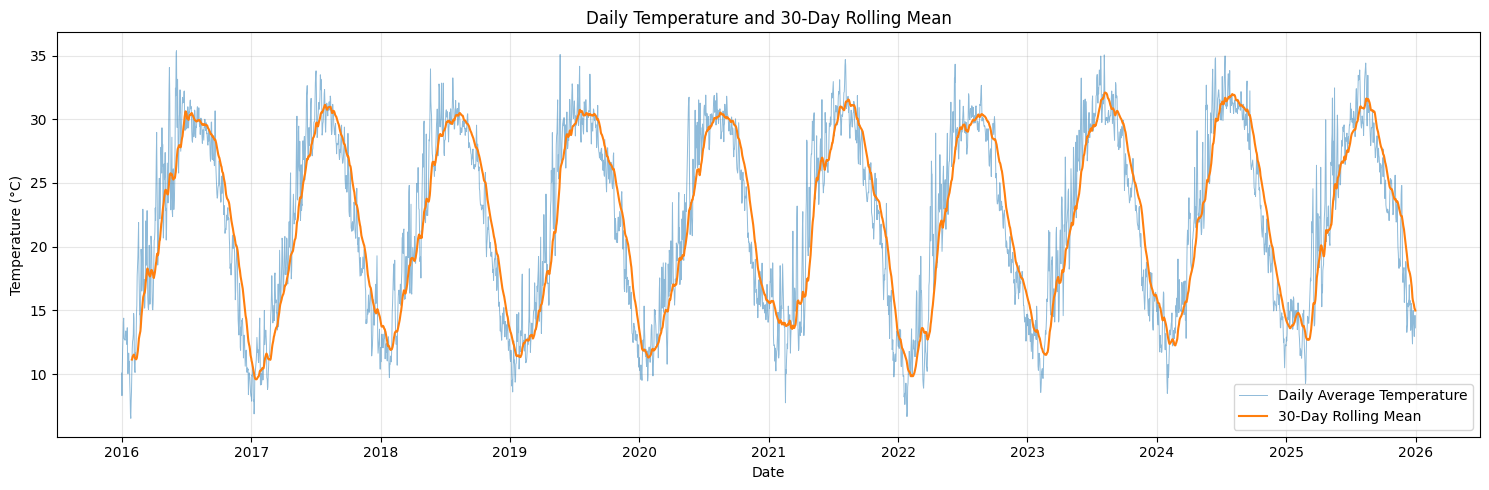

In [13]:
rolling_mean = target.rolling(window=30).mean()

plt.figure(figsize=(15, 5))

plt.plot(
    target.index,
    target,
    label="Daily Average Temperature",
    alpha=0.5,
    linewidth=0.7
)

plt.plot(
    rolling_mean.index,
    rolling_mean,
    label="30-Day Rolling Mean",
    linewidth=1.5
)

plt.title("Daily Temperature and 30-Day Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Seasonal Decomposition

Seasonal decomposition is applied to the daily average temperature series to separate it into trend, seasonal, and residual components.

A seasonal period of 365 days is used to investigate the approximate annual temperature pattern.

This analysis helps characterize the structure of the time series before conducting formal stationarity tests and building forecasting models.


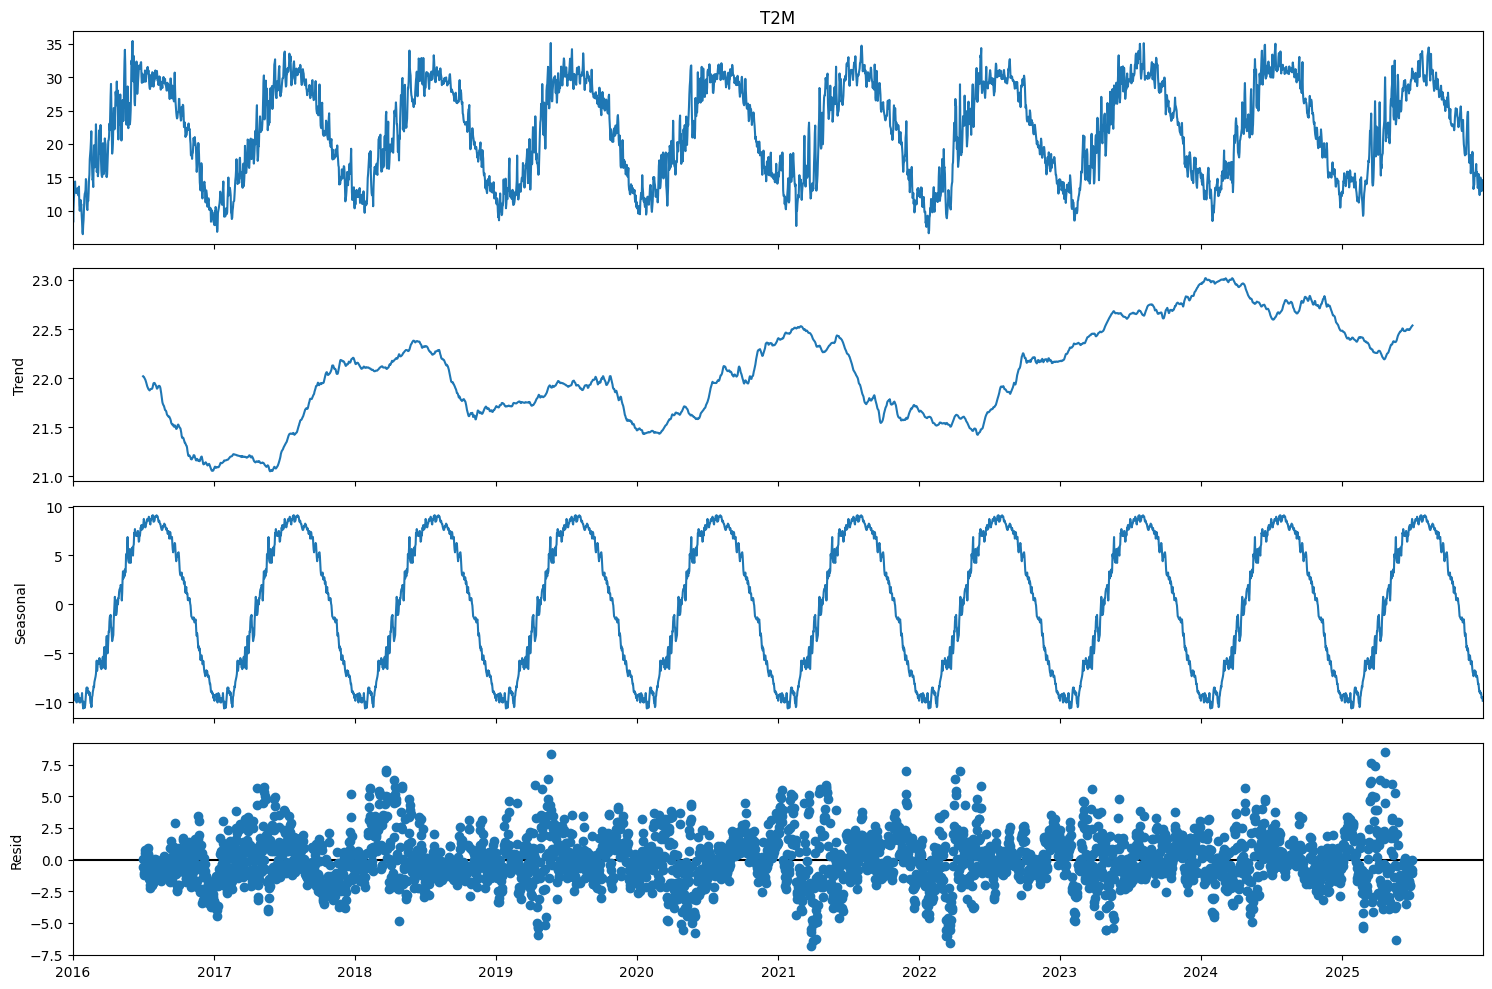

In [14]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    target,
    model="additive",
    period=365
)

decomposition.plot()
plt.gcf().set_size_inches(15, 10)
plt.tight_layout()
plt.show()

## 13. Stationarity Testing Using the ADF Test

The Augmented Dickey-Fuller (ADF) test is applied to the daily average temperature series to assess whether it contains a unit root.

The null hypothesis states that the series contains a unit root, while the alternative hypothesis states that it does not.

A significance level of 0.05 is used to interpret the test results.


In [15]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(target)

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:")

for key, value in adf_result[4].items():
    print(f"{key}: {value}")

if adf_result[1] < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("The series provides evidence against having a unit root.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("The series may contain a unit root.")

ADF Statistic: -4.302879402499686
p-value: 0.0004391398054432986
Critical Values:
1%: -3.4321567201852456
5%: -2.862338308122449
10%: -2.5671949518327932

Conclusion: Reject the null hypothesis.
The series provides evidence against having a unit root.


/tmp/ipykernel_3045/2266984628.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(target)


## 14. Stationarity Testing Using the KPSS Test

The KPSS test is applied as a complementary stationarity test.

Unlike the ADF test, the KPSS null hypothesis assumes that the series is stationary around a constant level.

The test results will be interpreted alongside the ADF results to obtain a more complete understanding of the temperature series.


In [16]:
from statsmodels.tsa.stattools import kpss

kpss_statistic, kpss_pvalue, kpss_lags, kpss_critical_values = kpss(
    target,
    regression="c",
    nlags="auto"
)

print("KPSS Statistic:", kpss_statistic)
print("p-value:", kpss_pvalue)
print("Number of Lags:", kpss_lags)

print("\nCritical Values:")
for key, value in kpss_critical_values.items():
    print(f"{key}: {value}")

if kpss_pvalue < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("The series shows evidence of non-stationarity around a constant level.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("The series is consistent with stationarity around a constant level.")

KPSS Statistic: 0.07161081050435436
p-value: 0.1
Number of Lags: 38

Critical Values:
10%: 0.347
5%: 0.463
2.5%: 0.574
1%: 0.739

Conclusion: Fail to reject the null hypothesis.
The series is consistent with stationarity around a constant level.


/tmp/ipykernel_3045/2208346134.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_statistic, kpss_pvalue, kpss_lags, kpss_critical_values = kpss(
/tmp/ipykernel_3045/2208346134.py:3: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_statistic, kpss_pvalue, kpss_lags, kpss_critical_values = kpss(


### Findings

* The KPSS test returned a statistic of 0.0716 and a reported p-value of 0.1.
* The test statistic is below the 5% critical value of 0.463.
* Therefore, we fail to reject the null hypothesis of stationarity around a constant level.
* The KPSS result is consistent with the ADF test result, which provided evidence against the presence of a unit root.
* However, the series still exhibits a clear annual seasonal pattern, as observed during time-series visualization and STL decomposition.
* The reported KPSS p-value is greater than 0.1, according to the warning generated by the test.


## 15. Autocorrelation Function (ACF)

The ACF plot examines the correlation between the daily average temperature series and its previous observations at different time lags.

It helps identify temporal dependencies and potential seasonal patterns that may be useful when selecting an appropriate time-series forecasting model.


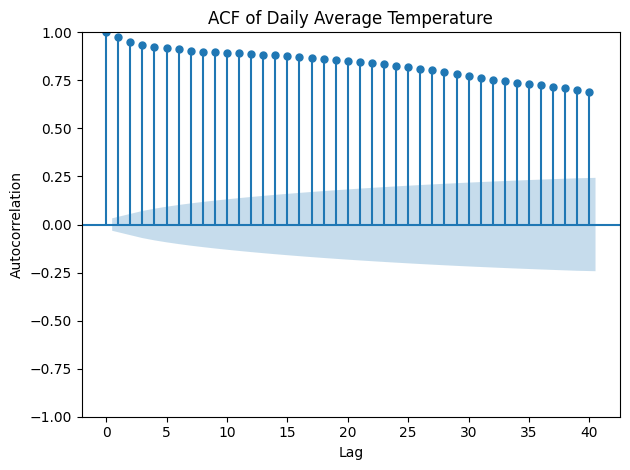

In [17]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(target, lags=40)

plt.title("ACF of Daily Average Temperature")
plt.xlabel("Lag")
plt.ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

## 16. Partial Autocorrelation Function (PACF)

The PACF plot examines the direct relationship between the daily average temperature series and its observations at different time lags, accounting for the effects of intermediate lags.

It complements the ACF plot and helps identify potential autoregressive (AR) terms when selecting a time-series forecasting model.


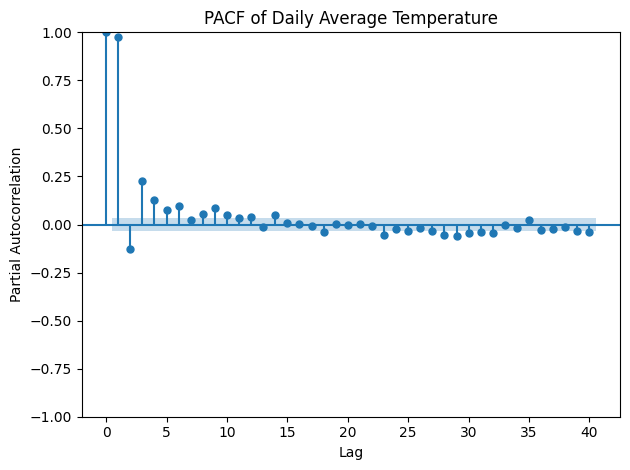

In [18]:
from statsmodels.graphics.tsaplots import plot_pacf

plot_pacf(target, lags=40, method="ywm")

plt.title("PACF of Daily Average Temperature")
plt.xlabel("Lag")
plt.ylabel("Partial Autocorrelation")
plt.tight_layout()
plt.show()

## 17. Time-Based Train-Test Split

The target series is divided into training and testing sets while preserving chronological order.

The first 80% of observations will be used for training, and the remaining 20% will be reserved for testing.

Shuffling is avoided to prevent future observations from being used to predict earlier observations.


In [19]:
split_index = int(len(target) * 0.8)

train = target.iloc[:split_index]
test = target_raw.iloc[split_index:]

print("Training Set Size:", len(train))
print("Testing Set Size:", len(test))

print("\nTraining Period:")
print("Start:", train.index.min())
print("End:", train.index.max())

print("\nTesting Period:")
print("Start:", test.index.min())
print("End:", test.index.max())

Training Set Size: 2922
Testing Set Size: 731

Training Period:
Start: 2016-01-01 00:00:00
End: 2023-12-31 00:00:00

Testing Period:
Start: 2024-01-01 00:00:00
End: 2025-12-31 00:00:00


## 18. Visualizing the Train-Test Split

The training and testing periods are visualized to confirm the chronological split.

The training set covers January 2016 to December 2023, while the testing set covers January 2024 to December 2025.

The testing observations will be used to evaluate the forecasting model on unseen data, while preserving the chronological order of the time series.


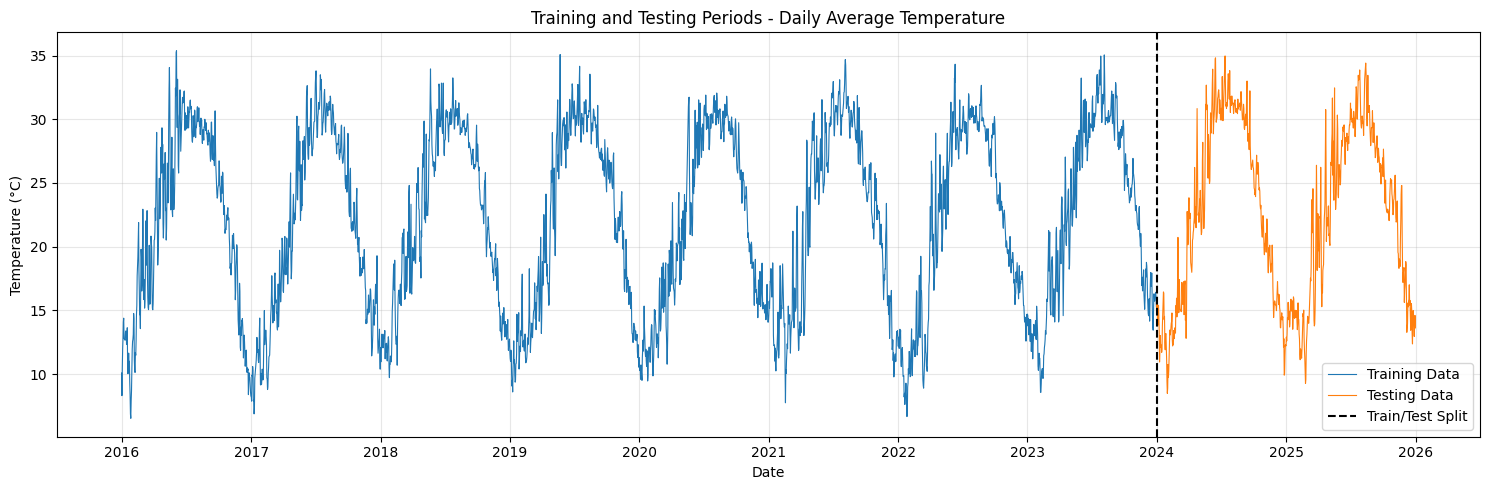

In [20]:
plt.figure(figsize=(15, 5))

plt.plot(train.index, train, label="Training Data", linewidth=0.8)
plt.plot(test.index, test, label="Testing Data", linewidth=0.8)

plt.axvline(
    x=test.index[0],
    color="black",
    linestyle="--",
    label="Train/Test Split"
)

plt.title("Training and Testing Periods - Daily Average Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 19. First Differencing

First differencing calculates the change between consecutive daily average temperature observations.

It is used to investigate whether differencing helps stabilize the time series. The decision to apply differencing in the forecasting model will be based on the stationarity tests and the observed characteristics of the series.


Original Series Length: 3653
Differenced Series Length: 3652

Differenced Series Statistics:


,T2M
count,3652.000000
mean,0.000972
std,1.461814
min,-7.950000
25%,-0.720000
50%,0.060000
75%,0.790000
max,6.410000


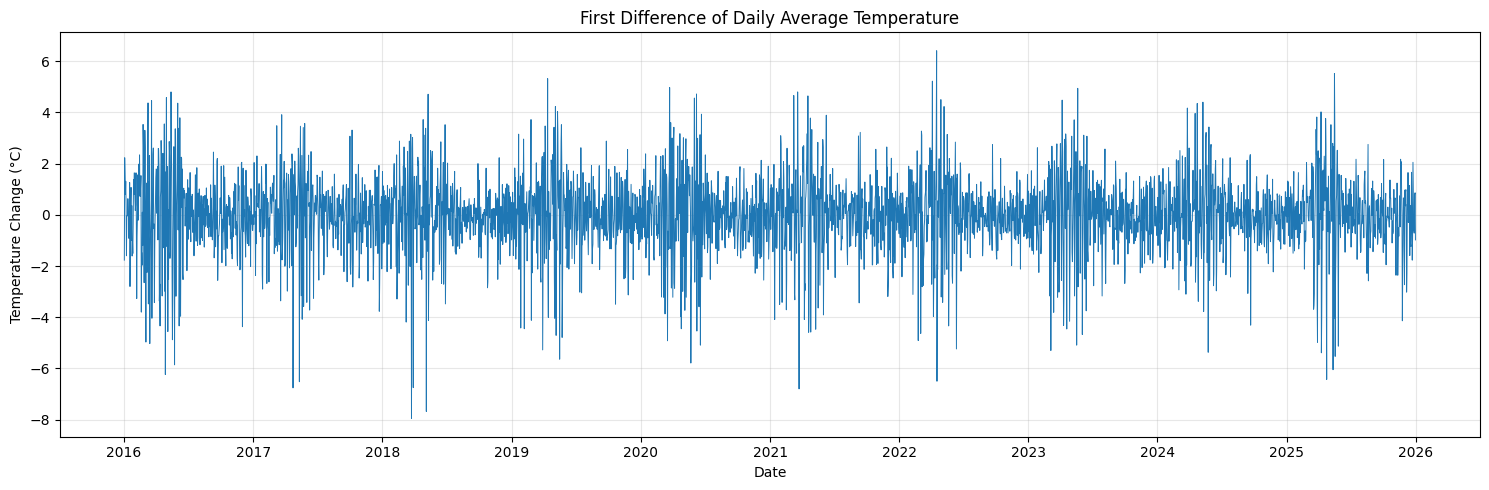

In [21]:
target_diff = target.diff().dropna()

print("Original Series Length:", len(target))
print("Differenced Series Length:", len(target_diff))

print("\nDifferenced Series Statistics:")
display(target_diff.describe())

plt.figure(figsize=(15, 5))
plt.plot(target_diff.index, target_diff, linewidth=0.7)

plt.title("First Difference of Daily Average Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature Change (°C)")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
adf_diff_result = adfuller(target_diff)

print("ADF Statistic:", adf_diff_result[0])
print("p-value:", adf_diff_result[1])

if adf_diff_result[1] < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("The differenced series provides evidence against a unit root.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("The differenced series may contain a unit root.")

ADF Statistic: -8.538285103296575
p-value: 9.94168780369791e-14

Conclusion: Reject the null hypothesis.
The differenced series provides evidence against a unit root.


/tmp/ipykernel_3045/2929553704.py:1: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_diff_result = adfuller(target_diff)


### Findings

* The ADF test on the first-differenced series returned a statistic of -8.5383 and a p-value of approximately 9.94 × 10⁻¹⁴.
* Since the p-value is below the 0.05 significance level, the null hypothesis is rejected.
* The result provides strong statistical evidence against the presence of a unit root in the differenced series.
* However, the original series also rejected the ADF null hypothesis. Therefore, first differencing is not automatically required, and the appropriate differencing order must be selected based on the overall time-series analysis and forecasting performance.

## 21. KPSS Test After First Differencing

The KPSS test is applied to the first-differenced temperature series to evaluate whether it is stationary around a constant level.

Unlike the ADF test, the KPSS test uses **stationarity as its null hypothesis**.

* **Null Hypothesis (H₀):** The differenced series is stationary around a constant level.
* **Alternative Hypothesis (H₁):** The differenced series is not stationary around a constant level.

We use a significance level of **0.05**:

* If the p-value is less than 0.05, we reject the null hypothesis, indicating evidence of non-stationarity.
* If the p-value is greater than or equal to 0.05, we fail to reject the null hypothesis, meaning the series is consistent with stationarity.

The KPSS result will be considered alongside the ADF result to help assess whether first differencing is necessary.


In [23]:
kpss_diff_result = kpss(
    target_diff,
    regression="c",
    nlags="auto"
)

kpss_diff_statistic = kpss_diff_result[0]
kpss_diff_pvalue = kpss_diff_result[1]

print("KPSS Statistic:", kpss_diff_statistic)
print("p-value:", kpss_diff_pvalue)

if kpss_diff_pvalue < 0.05:
    print("\nConclusion: Reject the null hypothesis.")
    print("The differenced series shows evidence of non-stationarity around a constant level.")
else:
    print("\nConclusion: Fail to reject the null hypothesis.")
    print("The differenced series is consistent with stationarity around a constant level.")

KPSS Statistic: 0.041980162115572074
p-value: 0.1

Conclusion: Fail to reject the null hypothesis.
The differenced series is consistent with stationarity around a constant level.


/tmp/ipykernel_3045/4036397774.py:1: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is greater than the p-value returned.
  kpss_diff_result = kpss(
/tmp/ipykernel_3045/4036397774.py:1: FutureWarning: kpss currently returns a plain tuple whose length and layout depends on the store argument (and which silently drops `lags` when store=True). In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning a KPSSResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  kpss_diff_result = kpss(


### Findings

* The KPSS test on the first-differenced series returned a statistic of 0.0420 and a reported p-value of 0.1.
* Since the reported p-value is greater than the 0.05 significance level, the null hypothesis is not rejected.
* The result is consistent with the first-differenced series being stationary around a constant level.
* The actual p-value is greater than 0.1, as indicated by the interpolation warning.
* Both the ADF and KPSS tests provide evidence consistent with stationarity in the first-differenced series. However, the original series also showed evidence against a unit root in the ADF test and was consistent with level-stationarity according to KPSS.
* Therefore, first differencing should not be considered automatically necessary. The final modeling decision should also account for the seasonal pattern and forecasting performance.

## 22. ACF and PACF Analysis for ARIMA Order Selection

The Autocorrelation Function (ACF) and Partial Autocorrelation Function (PACF) help identify potential autoregressive and moving average orders for ARIMA models.

* **ACF (Autocorrelation Function):** Measures the correlation between the time series and its past values at different lags. It helps identify potential Moving Average (MA) orders, represented by `q`.
* **PACF (Partial Autocorrelation Function):** Measures the direct correlation between the time series and a specific lag after accounting for the effects of intermediate lags. It helps identify potential Autoregressive (AR) orders, represented by `p`.
* **Differencing order (`d`):** Represents the number of times the series is differenced to help achieve stationarity.

For an ARIMA model, the parameters are represented as `ARIMA(p, d, q)`.

The ACF and PACF plots will be examined to suggest candidate values for `p` and `q`. These plots provide initial guidance rather than definitive model orders.

Since the temperature series exhibits annual seasonality, seasonal patterns must also be considered when selecting the final forecasting model.


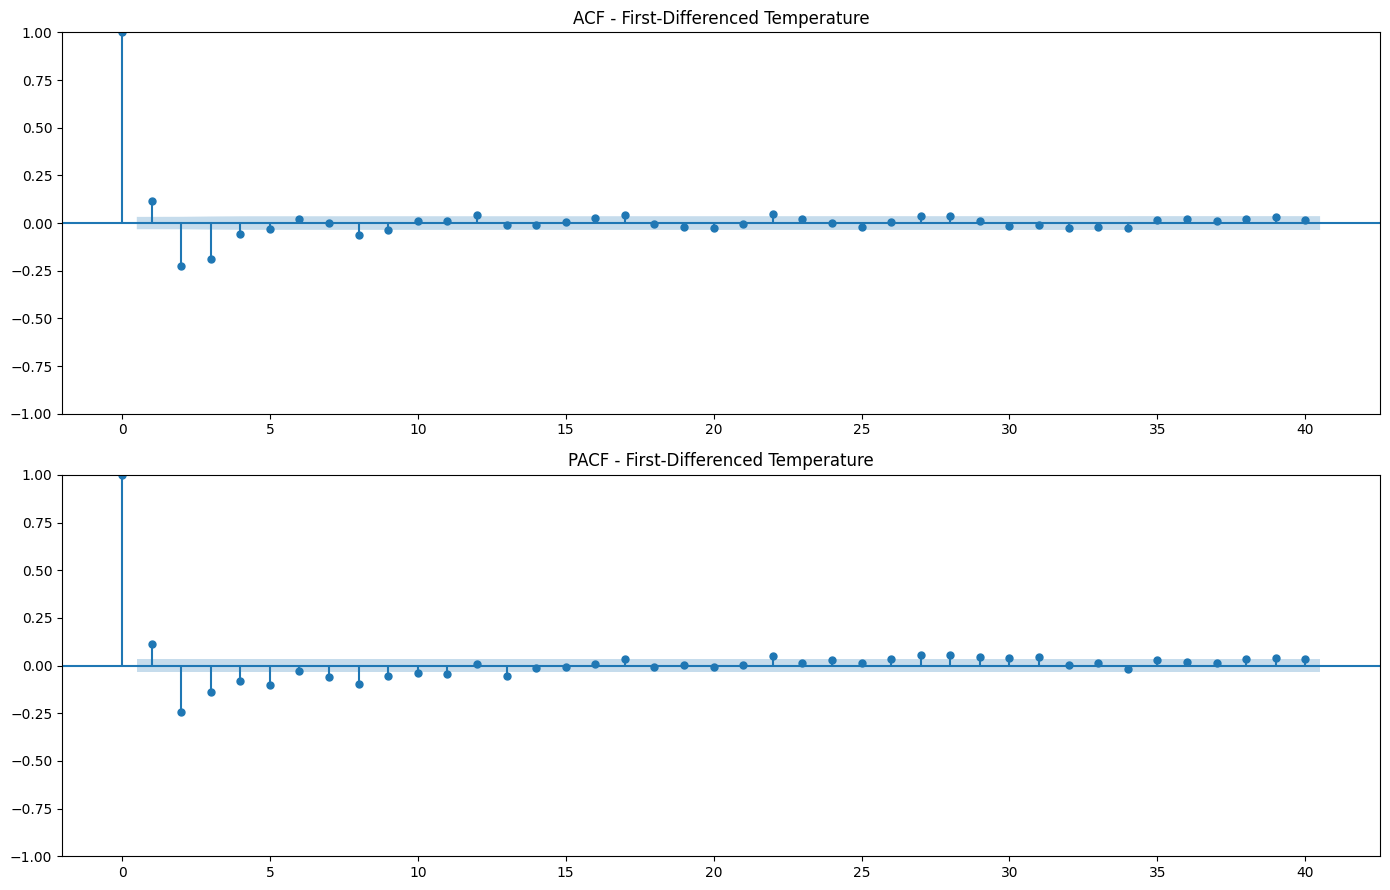

In [24]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(14, 9))

plot_acf(target_diff, lags=40, ax=axes[0])
axes[0].set_title("ACF - First-Differenced Temperature")

plot_pacf(target_diff, lags=40, method="ywm", ax=axes[1])
axes[1].set_title("PACF - First-Differenced Temperature")

plt.tight_layout()
plt.show()

### Seasonal check on ACF (annual cycle)

The default 40-lag plot cannot show an annual spike. We extend the ACF to lag 400 on the first-differenced series to look for a spike near lag 365.

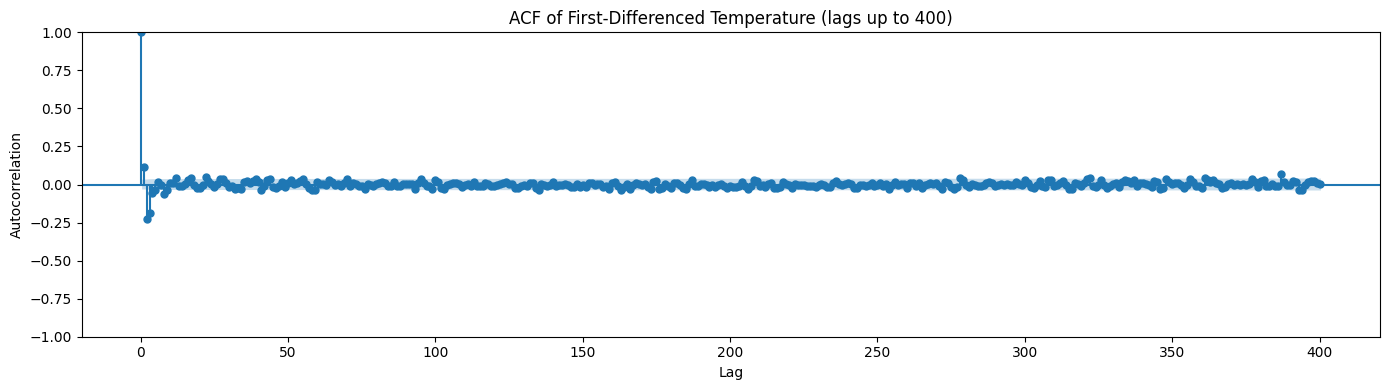

In [25]:
fig, ax = plt.subplots(figsize=(14, 4))
plot_acf(target_diff, lags=400, ax=ax)
ax.set_title("ACF of First-Differenced Temperature (lags up to 400)")
ax.set_xlabel("Lag")
ax.set_ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

### Manual reading of ACF / PACF (before auto_arima)

* Non-seasonal AR order p: The PACF tails off gradually with lag 2 as the strongest
  value, and significant lags continue up to about lag 13. This suggests a mixed
  ARMA process, so p is between 2 and 5.
* Differencing d: ADF rejects the unit root on the raw series and KPSS does not
  reject stationarity, so d = 0 is supported.
* Non-seasonal MA order q: The ACF cuts off after lag 3 (values at lags 1 to 3 are
  significant, then they drop below the bound), so q is around 2 to 3.
* Seasonal signal at lag 365: No clear spike appears at lag 365 in the first-differenced
  series; the strongest value near that lag (lag 356) is barely above the bound.
  Differencing removes much of the slow annual level, so the annual cycle is justified
  from the decomposition and the raw series rather than from this ACF alone.

## 23. Auto ARIMA Preparation

Auto ARIMA is a model selection approach that evaluates different ARIMA configurations and helps identify suitable model orders based on an information criterion, such as AIC.

The ARIMA model is represented by three parameters:

* `p`: Autoregressive (AR) order.
* `d`: Differencing order.
* `q`: Moving Average (MA) order.

Since the daily average temperature series exhibits annual seasonality, a seasonal model such as SARIMA may also be appropriate.

Before proceeding, we will check whether the `pmdarima` library is installed in the current Python environment.


In [26]:
try:
    import pmdarima
    print("pmdarima is installed.")
except ImportError:
    print("pmdarima is not installed.")

pmdarima is not installed.


## 24. Installing the pmdarima Library

The `pmdarima` library provides the `auto_arima` function, which helps select suitable ARIMA model parameters automatically.

We will install this library to support the model selection stage of the time-series forecasting workflow.

**Note:** The installation command must run in the same Python environment used by the current Jupyter Notebook.


In [27]:
%pip install pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 34.2 MB/s eta 0:00:00


In [28]:
from pmdarima import auto_arima

print("auto_arima imported successfully.")

auto_arima imported successfully.


## 26. Auto ARIMA Model Selection

Auto ARIMA helps identify suitable ARIMA model orders by evaluating different parameter combinations using an information criterion such as AIC.

The model parameters are:

* `p`: Autoregressive order.
* `d`: Differencing order.
* `q`: Moving Average order.

For seasonal models, SARIMA introduces additional parameters:

* `P`: Seasonal autoregressive order.
* `D`: Seasonal differencing order.
* `Q`: Seasonal moving average order.
* `m`: Seasonal period.

The original temperature series exhibits an annual seasonal pattern. Therefore, seasonal effects must be considered when selecting the final forecasting model.

We will begin with a non-seasonal Auto ARIMA search using the training data only. Its results will serve as a baseline for comparison with seasonal modeling.

The test set will remain untouched during model selection to avoid data leakage.


In [29]:
auto_arima_model = auto_arima(
    train,
    seasonal=False,
    d=None,
    max_p=5,
    max_q=5,
    max_d=2,
    start_p=0,
    start_q=0,
    information_criterion="aic",
    stepwise=True,
    suppress_warnings=True,
    error_action="ignore",
    trace=True
)

print("\nBest ARIMA Model:")
print(auto_arima_model.summary())

Performing stepwise search to minimize aic
 ARIMA(0,0,0)(0,0,0)[0]             : AIC=26635.949, Time=0.08 sec
 ARIMA(1,0,0)(0,0,0)[0]             : AIC=inf, Time=0.08 sec
 ARIMA(0,0,1)(0,0,0)[0]             : AIC=22815.863, Time=0.37 sec
 ARIMA(1,0,1)(0,0,0)[0]             : AIC=10536.260, Time=0.23 sec
 ARIMA(2,0,1)(0,0,0)[0]             : AIC=10508.659, Time=1.63 sec
 ARIMA(2,0,0)(0,0,0)[0]             : AIC=inf, Time=0.18 sec
 ARIMA(3,0,1)(0,0,0)[0]             : AIC=10247.715, Time=1.48 sec
 ARIMA(3,0,0)(0,0,0)[0]             : AIC=inf, Time=0.23 sec
 ARIMA(4,0,1)(0,0,0)[0]             : AIC=10243.474, Time=1.92 sec
 ARIMA(4,0,0)(0,0,0)[0]             : AIC=inf, Time=0.39 sec
 ARIMA(5,0,1)(0,0,0)[0]             : AIC=10244.880, Time=6.33 sec
 ARIMA(4,0,2)(0,0,0)[0]             : AIC=10198.805, Time=5.74 sec
 ARIMA(3,0,2)(0,0,0)[0]             : AIC=10244.512, Time=2.02 sec
 ARIMA(5,0,2)(0,0,0)[0]             : AIC=10243.125, Time=8.65 sec
 ARIMA(4,0,3)(0,0,0)[0]             : AIC=1

The auto_arima search (seasonal=False) selected ARIMA(4,0,2) with d=0, which is consistent with the manual reading. The AR coefficients sum to approximately 1, suggesting the model compensates for the missing annual cycle with high persistence. Residual diagnostics show remaining autocorrelation and non-normality, so the seasonal Fourier model is needed.

## 27. Evaluating the ARIMA Model

In this section, we will evaluate the selected non-seasonal ARIMA model using the held-out test set.

The model was fitted using daily average temperature data from 2016 to 2023. We will generate forecasts for the test period from 2024 to 2025 and compare the predicted temperatures with the actual observations.

This evaluation will help us understand how well the model forecasts unseen data.


In [30]:
# Generate forecasts for the test period
forecast = auto_arima_model.predict(n_periods=len(test))

# Match forecast dates with the test set
forecast = pd.Series(forecast, index=test.index, name="Forecast")

print("Forecast length:", len(forecast))
print("Test length:", len(test))

display(pd.DataFrame({
    "Actual Temperature": test,
    "Forecast Temperature": forecast
}).head(10))

Forecast length: 731
Test length: 731


,Actual Temperature,Forecast Temperature
date,,
2024-01-01,14.91,14.856746
2024-01-02,15.59,14.647217
2024-01-03,14.39,14.545870
2024-01-04,14.18,14.485692
2024-01-05,13.86,14.435057
2024-01-06,15.40,14.382417
2024-01-07,14.60,14.325486
2024-01-08,13.45,14.265241
2024-01-09,10.95,14.203213


## 28. Forecast Evaluation Metrics

We will evaluate the ARIMA model using Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE).

* MAE measures the average absolute difference between actual and forecast temperatures.
* RMSE penalizes larger forecasting errors more heavily.

Both metrics are expressed in degrees Celsius (°C). Lower values indicate better forecasting performance.


In [31]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(test, forecast)

rmse = np.sqrt(mean_squared_error(test, forecast))

print(f"MAE: {mae:.4f} °C")
print(f"RMSE: {rmse:.4f} °C")

MAE: 17.1639 °C
RMSE: 18.9636 °C


## 29. Visual Comparison of Actual and Forecast Temperatures

In this section, we will plot the actual and forecast temperatures over the test period.

The visualization will help us determine whether the model captures the temperature variations and annual seasonal pattern or produces forecasts that remain relatively stable.


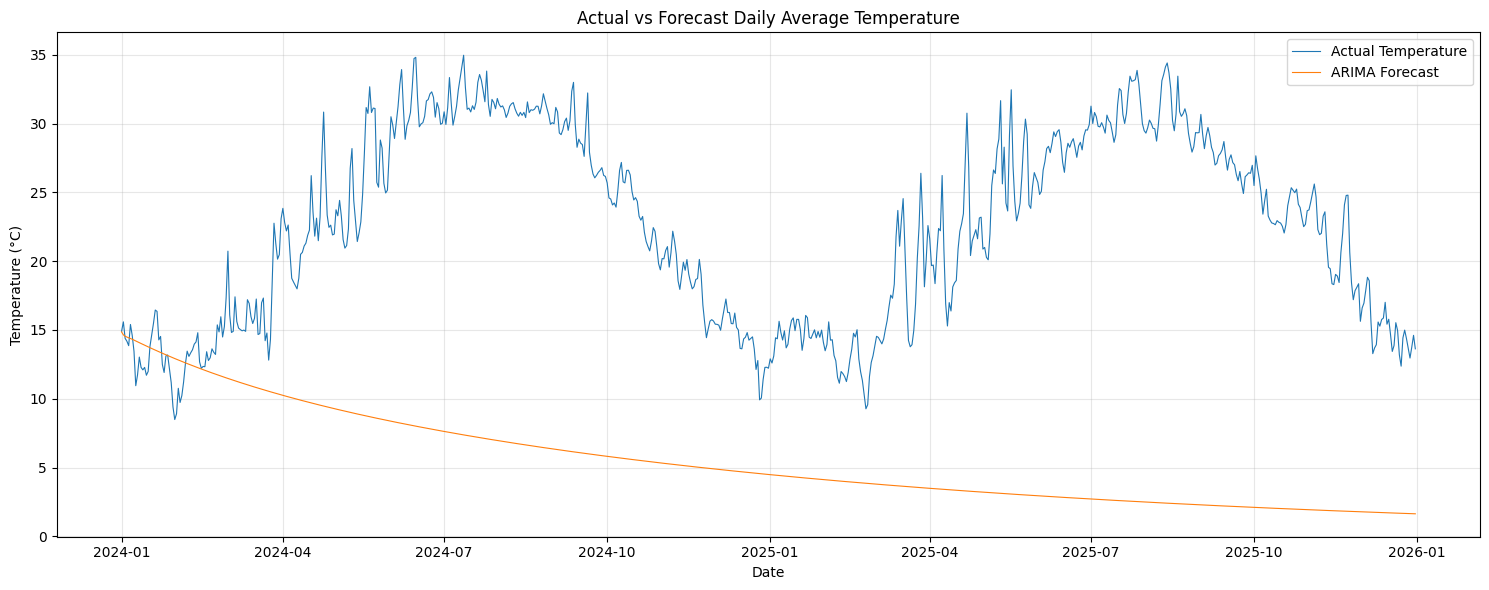

In [32]:
plt.figure(figsize=(15, 6))

plt.plot(test.index, test, label="Actual Temperature", linewidth=0.8)
plt.plot(forecast.index, forecast, label="ARIMA Forecast", linewidth=0.8)

plt.title("Actual vs Forecast Daily Average Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 30. Seasonal Modeling with SARIMA

The original temperature series shows a clear annual seasonal pattern. The non-seasonal ARIMA model did not capture this pattern effectively during long-term forecasting.

SARIMA extends ARIMA by including seasonal components. Since the dataset contains daily temperature observations, the annual seasonal period is approximately 365 days.

The next step is to fit a seasonal model and compare its forecasting performance with the non-seasonal ARIMA model using MAE and RMSE.


## 31. SARIMA Model Configuration

The SARIMA model combines non-seasonal and seasonal components. Fitting a full seasonal model with a period of 365 is computationally expensive, so the annual cycle is modeled with Fourier terms passed as exogenous regressors.

The following parameters are used:

* **Non-seasonal order:** (1, 0, 1)
* **Seasonal component:** Fourier terms with K = 3 harmonics (sin and cos of the day of year)
* **Trend:** constant (intercept), to capture the mean temperature level
* **Training data:** 2016 to 2023 (outlier-treated)
* **Testing data:** 2024 to 2025 (raw observations)

The model is evaluated using MAE and RMSE and compared with the seasonal naive baseline and the non-seasonal ARIMA.

In [33]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

def fourier_features(index, K=3, period=365.25):
    doy = index.dayofyear.values
    feats = {}
    for k in range(1, K + 1):
        feats[f"sin_{k}"] = np.sin(2 * np.pi * k * doy / period)
        feats[f"cos_{k}"] = np.cos(2 * np.pi * k * doy / period)
    return pd.DataFrame(feats, index=index)

X_train_f = fourier_features(train.index, K=3)
X_test_f = fourier_features(test.index, K=3)

print("Fourier train shape:", X_train_f.shape)
print("Fourier test shape:", X_test_f.shape)

Fourier train shape: (2922, 6)
Fourier test shape: (731, 6)


## 32. Fitting the SARIMA Model

In this step, the SARIMA model is fitted using the training data from 2016 to 2023.

The model will learn the temporal and seasonal patterns in the historical daily temperature series.


In [34]:
sarima_model = SARIMAX(
    train,
    exog=X_train_f,
    order=(1, 0, 1),
    trend='c',
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_fitted = sarima_model.fit(disp=False, maxiter=200)

print("SARIMAX with Fourier seasonality fitted successfully.")
print(sarima_fitted.summary())

SARIMAX with Fourier seasonality fitted successfully.
                               SARIMAX Results                                
Dep. Variable:                    T2M   No. Observations:                 2922
Model:               SARIMAX(1, 0, 1)   Log Likelihood               -5010.112
Date:                Thu, 22 Oct 2026   AIC                          10040.224
Time:                        10:30:29   BIC                          10100.018
Sample:                    01-01-2016   HQIC                         10061.761
                         - 12-31-2023                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      7.5145      0.322     23.324      0.000       6.883       8.146
sin_1         -3.7894      0.171    -22.184      0.000      -4.124      -3.45

In [35]:
print("Train mean:", round(train.mean(), 3))
print("Fitted mean:", round(sarima_fitted.fittedvalues.mean(), 3))
print("Fitted vs actual (first 5 rows):")
display(pd.DataFrame({
    "actual": train.head(5),
    "fitted": sarima_fitted.fittedvalues.head(5)
}))
print(X_train_f.head(3))

Train mean: 21.978
Fitted mean: 21.972
Fitted vs actual (first 5 rows):


,actual,fitted
date,,
2016-01-01,10.08,-9.385452
2016-01-02,8.31,10.874745
2016-01-03,10.54,9.690758
2016-01-04,11.99,11.391292
2016-01-05,12.78,12.272233


               sin_1     cos_1     sin_2     cos_2     sin_3     cos_3
date                                                                  
2016-01-01  0.017202  0.999852  0.034398  0.999408  0.051584  0.998669
2016-01-02  0.034398  0.999408  0.068755  0.997634  0.103031  0.994678
2016-01-03  0.051584  0.998669  0.103031  0.994678  0.154204  0.988039


## 33. SARIMA Forecasting

In this step, the fitted SARIMAX model generates temperature forecasts for the test period (2024 to 2025). The Fourier regressors for the test period are passed through the `exog` argument, so the annual cycle is carried into the forecast.

The forecasts are compared with the actual daily average temperatures to evaluate the model's performance.

In [36]:
sarima_forecast = sarima_fitted.get_forecast(steps=len(test), exog=X_test_f)

sarima_predictions = pd.Series(
    sarima_forecast.predicted_mean.to_numpy(),
    index=test.index,
    name="SARIMA Forecast"
)

print("Forecast length:", len(sarima_predictions))
print("Test length:", len(test))

display(pd.DataFrame({
    "Actual Temperature": test,
    "SARIMA Forecast": sarima_predictions
}).head(10))

Forecast length: 731
Test length: 731


,Actual Temperature,SARIMA Forecast
date,,
2024-01-01,14.91,14.374933
2024-01-02,15.59,13.701668
2024-01-03,14.39,13.239553
2024-01-04,14.18,12.917710
2024-01-05,13.86,12.689490
2024-01-06,15.40,12.524185
2024-01-07,14.60,12.401588
2024-01-08,13.45,12.308392
2024-01-09,10.95,12.235840


## 34. SARIMA Model Evaluation

In this step, the SARIMA forecasts are evaluated using two metrics:

* **MAE (Mean Absolute Error):** Measures the average absolute difference between actual and predicted temperatures.
* **RMSE (Root Mean Squared Error):** Measures prediction errors while penalizing larger errors more heavily.

Lower MAE and RMSE values indicate better forecasting performance.


In [37]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

sarima_mae = mean_absolute_error(test, sarima_predictions)

sarima_rmse = np.sqrt(
    mean_squared_error(test, sarima_predictions)
)

print(f"SARIMA MAE: {sarima_mae:.4f} °C")
print(f"SARIMA RMSE: {sarima_rmse:.4f} °C")

SARIMA MAE: 1.6093 °C
SARIMA RMSE: 2.1624 °C


## 34b. Seasonal Naive Baseline

A seasonal naive forecast predicts each day as the value from the same day one year earlier. Any model should beat this baseline before its results are considered useful.

In [38]:
naive_index = test.index - pd.DateOffset(years=1)
snaive_predictions = pd.Series(
    target_raw.reindex(naive_index).to_numpy(),
    index=test.index,
    name="Seasonal Naive"
)

print("Missing naive values:", int(snaive_predictions.isna().sum()))

snaive_mae = mean_absolute_error(test, snaive_predictions)
snaive_rmse = np.sqrt(mean_squared_error(test, snaive_predictions))

print(f"Seasonal Naive MAE: {snaive_mae:.4f} °C")
print(f"Seasonal Naive RMSE: {snaive_rmse:.4f} °C")

Missing naive values: 0
Seasonal Naive MAE: 2.2851 °C
Seasonal Naive RMSE: 2.9134 °C


## 35. Model Comparison

The forecasting performance of the models is compared using MAE and RMSE on the same 731-day test period. The training data is outlier-treated, while the test observations are the raw values.

| Model                             | MAE (°C) | RMSE (°C) |
| --------------------------------- | -------: | --------: |
| Seasonal Naive (t-365)            |   2.2851 |    2.9134 |
| ARIMA(4, 0, 2)                    |  17.1639 |   18.9636 |
| SARIMAX(1, 0, 1) + Fourier (K=3)  |   1.6093 |    2.1624 |

The SARIMAX model reduces the MAE by about 30% compared with the seasonal naive baseline, and by about 91% compared with the non-seasonal ARIMA. The ARIMA forecast reverts toward the mean over the two-year horizon, while the SARIMAX forecast follows the annual cycle.

In [39]:
comparison = pd.DataFrame({
    "Model": [
        "Seasonal Naive (t-365)",
        "ARIMA(4, 0, 2)",
        "SARIMAX(1, 0, 1) + Fourier (K=3)"
    ],
    "MAE (°C)": [snaive_mae, mae, sarima_mae],
    "RMSE (°C)": [snaive_rmse, rmse, sarima_rmse]
})

display(comparison.round(4))

,Model,MAE (°C),RMSE (°C)
0,Seasonal Naive (t-365),2.2851,2.9134
1,"ARIMA(4, 0, 2)",17.1639,18.9636
2,"SARIMAX(1, 0, 1) + Fourier (K=3)",1.6093,2.1624


## 36. Visualizing SARIMA Forecasts

This plot compares the actual daily average temperatures with the SARIMA model's predictions over the test period (2024–2025).

The visualization helps identify whether the model captures temperature fluctuations and seasonal patterns.


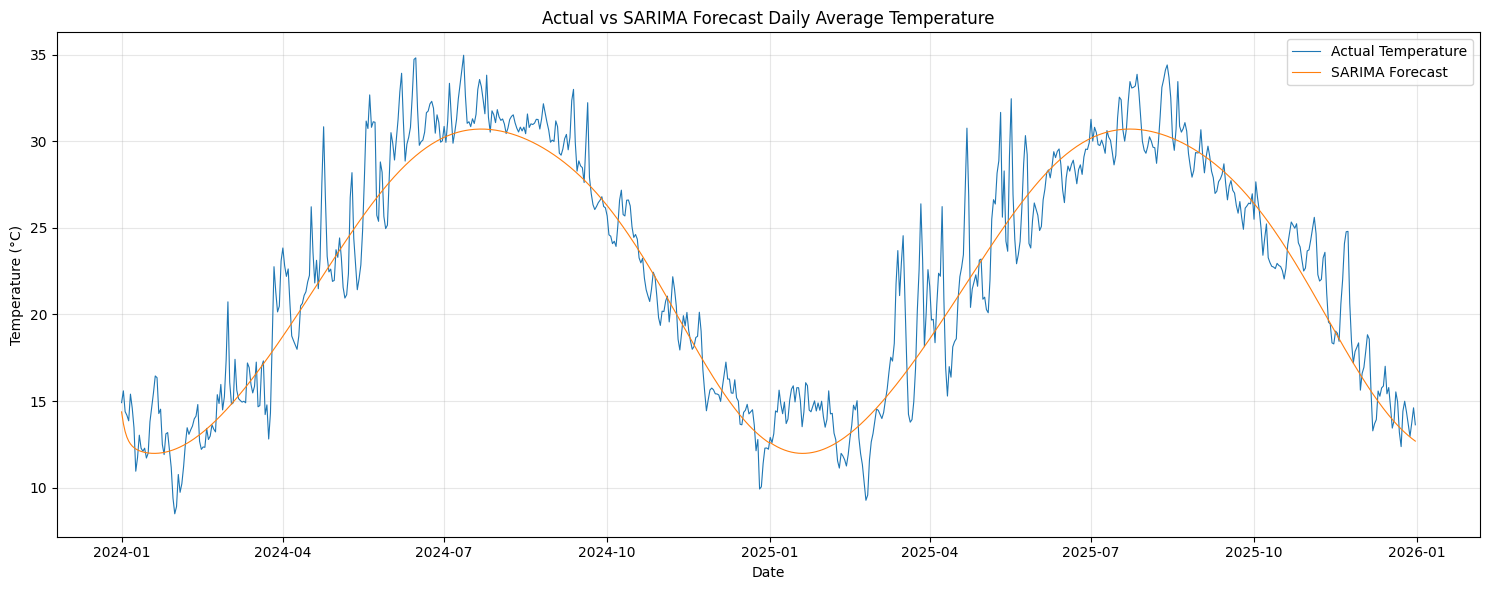

In [40]:
plt.figure(figsize=(15, 6))

plt.plot(test.index, test, label="Actual Temperature", linewidth=0.8)
plt.plot(
    sarima_predictions.index,
    sarima_predictions,
    label="SARIMA Forecast",
    linewidth=0.8
)

plt.title("Actual vs SARIMA Forecast Daily Average Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 37. SARIMA Forecast Visualization Findings

The actual temperature series shows a clear annual cycle, with summer peaks and winter lows. The SARIMAX forecast follows this cycle closely, while the non-seasonal ARIMA forecast flattens toward the mean.

The SARIMAX model achieves an MAE of 1.6093 °C and an RMSE of 2.1624 °C on the test period. These values are lower than both the seasonal naive baseline (MAE 2.2851 °C) and the non-seasonal ARIMA (MAE 17.1639 °C).

## 38. Residual Diagnostics — Ljung–Box Test

Residual diagnostics help determine whether the fitted ARIMA model has captured the important temporal patterns in the training data.

The Ljung–Box test checks whether the residuals contain significant autocorrelation.

* **Null hypothesis (H₀):** The residuals have no autocorrelation up to the tested lags.
* **Alternative hypothesis (H₁):** The residuals contain autocorrelation.

A p-value greater than 0.05 means we fail to reject the null hypothesis. A p-value of 0.05 or lower indicates evidence of remaining autocorrelation.


In [41]:
from statsmodels.stats.diagnostic import acorr_ljungbox

arima_residuals = auto_arima_model.arima_res_.resid

ljung_box_results = acorr_ljungbox(
    arima_residuals,
    lags=[10, 20],
    return_df=True
)

display(ljung_box_results)

,lb_stat,lb_pvalue
10,41.077738,0.000011
20,57.973057,0.000015


## 39. Ljung–Box Test Findings

The Ljung–Box test returned p-values below 0.05 at both lag 10 and lag 20.

Therefore, the null hypothesis of no residual autocorrelation is rejected at both tested lags.

These results indicate that the ARIMA model residuals still contain temporal patterns that the model has not fully captured. This is consistent with the model's limited ability to represent the annual seasonality in daily temperature data.

Further model improvements may be needed to capture the remaining temporal structure.


In [42]:
arima_forecast_result = auto_arima_model.arima_res_.get_forecast(
    steps=len(test)
)

forecast_mean = arima_forecast_result.predicted_mean
confidence_intervals = arima_forecast_result.conf_int()

print("Forecast:")
display(forecast_mean.head())

print("Confidence Intervals:")
display(confidence_intervals.head())

Forecast:


,predicted_mean
2024-01-01,14.856746
2024-01-02,14.647217
2024-01-03,14.545870
2024-01-04,14.485692
2024-01-05,14.435057


Confidence Intervals:


,lower y,upper y
2024-01-01,12.151114,17.562378
2024-01-02,10.787561,18.506873
2024-01-03,10.164333,18.927407
2024-01-04,9.875704,19.095680
2024-01-05,9.712653,19.157461


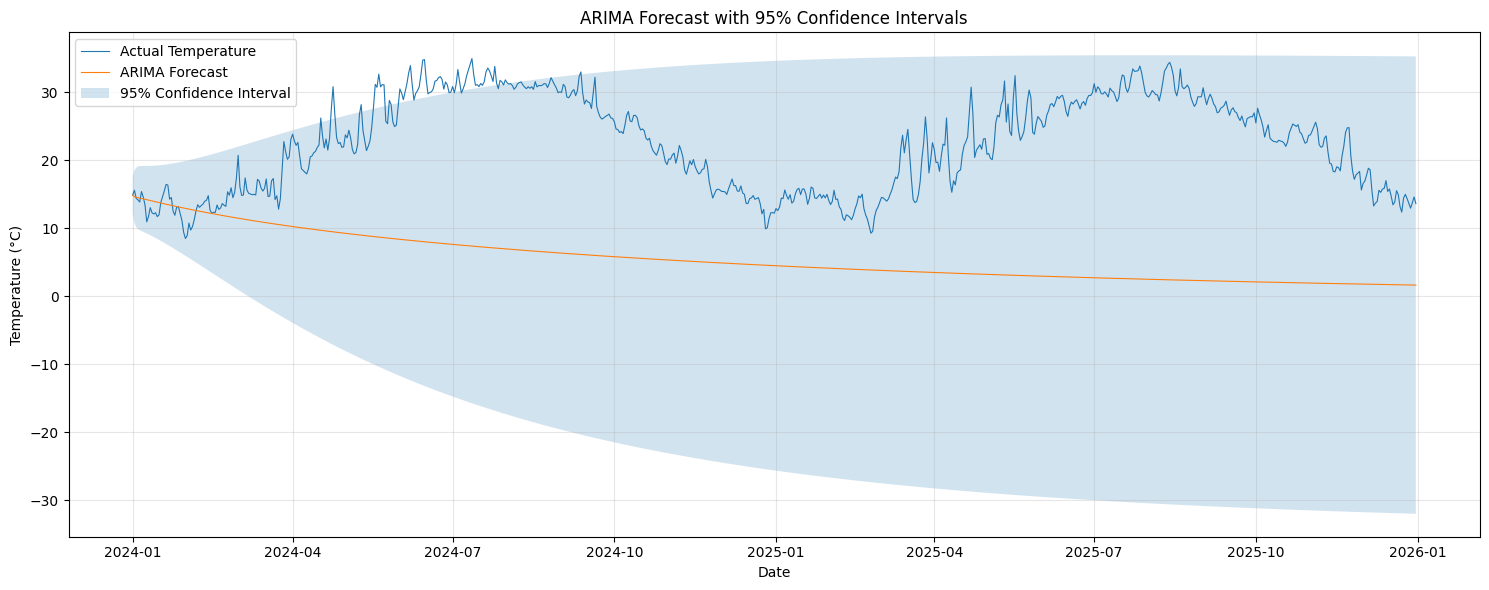

In [43]:
plt.figure(figsize=(15, 6))

plt.plot(test.index, test, label="Actual Temperature", linewidth=0.8)
plt.plot(forecast_mean.index, forecast_mean, label="ARIMA Forecast", linewidth=0.8)

plt.fill_between(
    forecast_mean.index,
    confidence_intervals.iloc[:, 0],
    confidence_intervals.iloc[:, 1],
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.title("ARIMA Forecast with 95% Confidence Intervals")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 39b. Residual Diagnostics — SARIMAX with Fourier Features

Residual diagnostics are used to assess whether the fitted SARIMAX model has captured the main temporal patterns in the training data.

The residuals represent the differences between the observed training temperatures and the values fitted by the model.

We will examine the residuals over time, their distribution, and their autocorrelation using diagnostic plots. We will also apply the Ljung–Box test to check whether significant autocorrelation remains.

* **Residuals over time:** Help identify remaining patterns or changes in error variability.
* **Histogram and Q-Q plot:** Help assess whether the residuals approximately follow a normal distribution.
* **Residual correlogram:** Helps identify remaining autocorrelation.
* **Ljung–Box test:** Tests the null hypothesis that the residuals have no autocorrelation up to the specified lags.

A p-value greater than 0.05 indicates insufficient evidence to reject the null hypothesis at the tested lags.


Number of Residuals: 2922
Residual Mean: 0.0057
Residual Standard Deviation: 1.3935


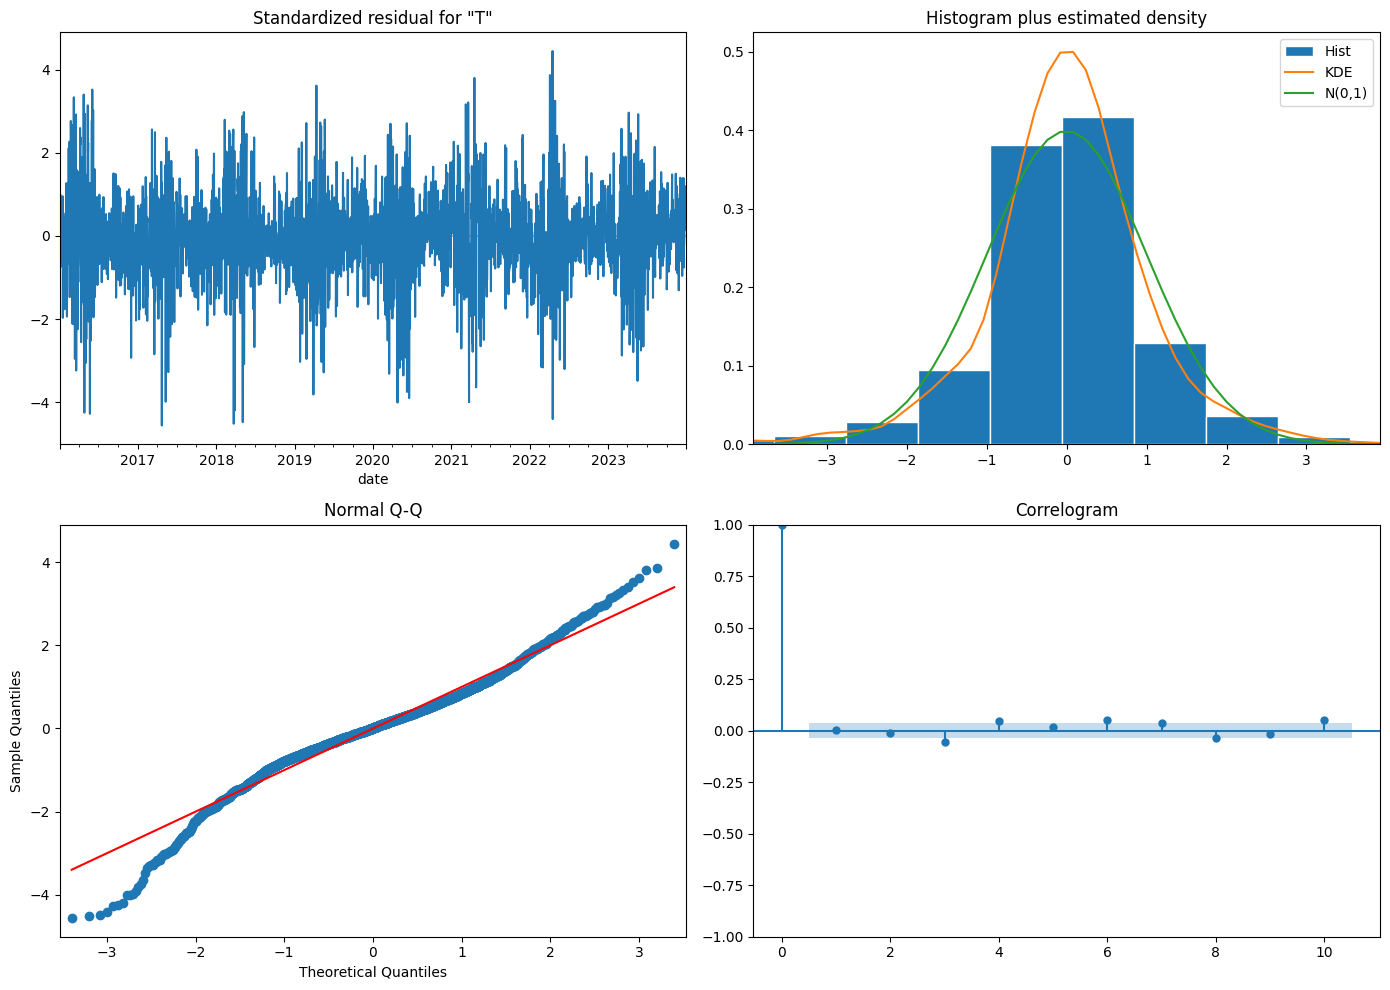

,lb_stat,lb_pvalue
10,35.181032,1.162864e-04
30,86.004120,2.614535e-07
90,179.315987,6.855079e-08


In [44]:
from statsmodels.stats.diagnostic import acorr_ljungbox
import matplotlib.pyplot as plt

# Extract residuals from the fitted SARIMAX model
sarima_residuals = sarima_fitted.resid.dropna()

# Display residual statistics
print("Number of Residuals:", len(sarima_residuals))
print("Residual Mean:", round(sarima_residuals.mean(), 4))
print("Residual Standard Deviation:", round(sarima_residuals.std(), 4))

# Plot residual diagnostics
sarima_fitted.plot_diagnostics(figsize=(14, 10))
plt.tight_layout()
plt.show()

# Ljung-Box test at selected daily lags
ljung_box_sarima = acorr_ljungbox(
    sarima_residuals,
    lags=[10, 30, 90],
    return_df=True
)

display(ljung_box_sarima)

### Findings

* The Ljung–Box test was performed on the residuals of the SARIMAX model with Fourier features at lags 10, 30, and 90.
* All three tests returned p-values below the 0.05 significance level. Therefore, the null hypothesis of no autocorrelation up to the tested lags was rejected.
* The standardized residuals fluctuate around zero, although some periods show larger variations and extreme values.
* The residual histogram and Q-Q plot indicate deviations from a normal distribution, particularly in the tails.
* Most autocorrelation coefficients shown in the residual correlogram are close to zero and fall within the displayed confidence bounds. However, the Ljung–Box results indicate that significant autocorrelation remains in the residuals.
* These findings suggest that the model has not captured all temporal patterns in the data. Further model refinement may be beneficial.
* Nevertheless, residual diagnostics should be considered alongside out-of-sample forecasting metrics when evaluating the model's overall effectiveness.


## 40. Mean Absolute Percentage Error (MAPE)

The Mean Absolute Percentage Error (MAPE) measures the average percentage difference between actual and predicted temperatures.

A lower MAPE indicates better predictive accuracy. However, MAPE should be interpreted alongside MAE and RMSE to evaluate the ARIMA model comprehensively.


In [45]:
from sklearn.metrics import mean_absolute_percentage_error

mape = mean_absolute_percentage_error(test, forecast) * 100

print(f"ARIMA MAPE: {mape:.2f}%")

ARIMA MAPE: 72.21%


## 40b. SARIMAX Forecast with 95% Confidence Intervals

Confidence intervals represent the uncertainty surrounding the model's forecasts.

In this section, we will visualize the SARIMAX predictions alongside the actual temperatures and their 95% confidence intervals over the test period (2024–2025).

The confidence intervals help assess the uncertainty of the forecasts. They do not guarantee that every future observation will fall within the interval.

,Actual Temperature,SARIMAX Forecast,Lower 95% CI,Upper 95% CI
date,,,,
2024-01-01,14.91,14.374933,11.737630,17.012235
2024-01-02,15.59,13.701668,10.000800,17.402535
2024-01-03,14.39,13.239553,9.163179,17.315927
2024-01-04,14.18,12.917710,8.688996,17.146425
2024-01-05,13.86,12.689490,8.396455,16.982524
2024-01-06,15.40,12.524185,8.203583,16.844787
2024-01-07,14.60,12.401588,8.069097,16.734078
2024-01-08,13.45,12.308392,7.970761,16.646023
2024-01-09,10.95,12.235840,7.895984,16.575696


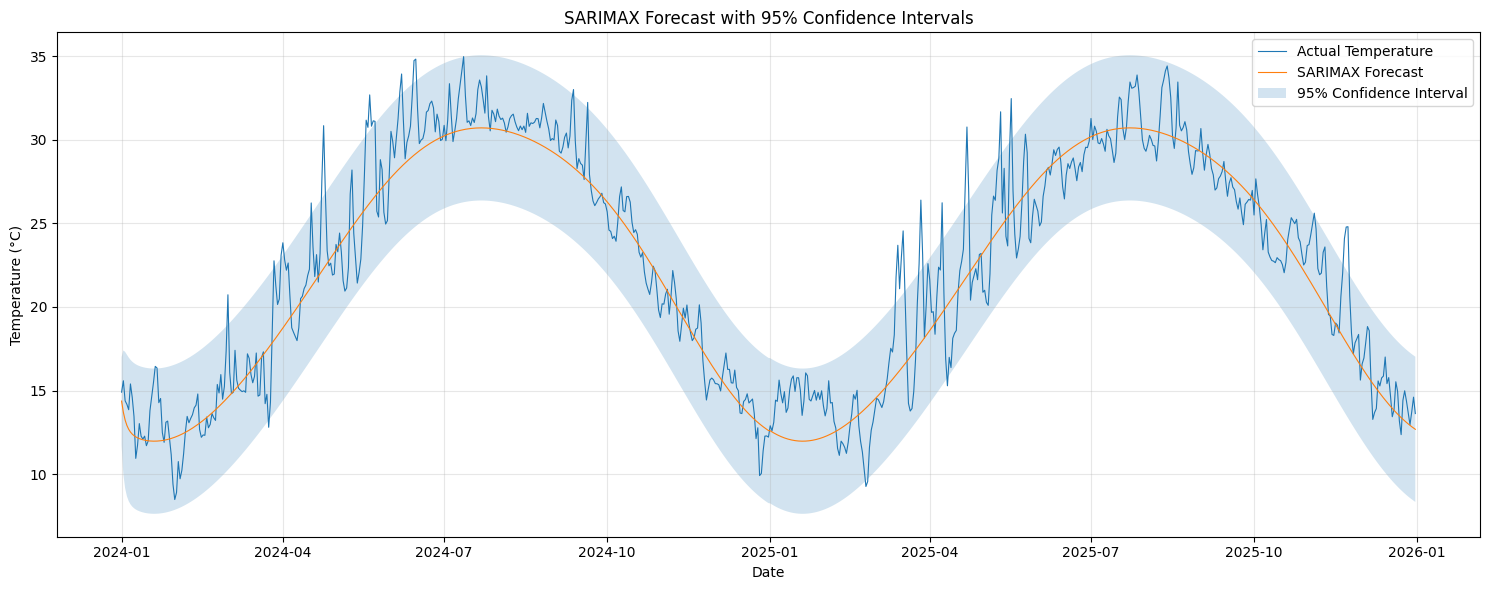

In [46]:
# Generate SARIMAX forecasts with 95% confidence intervals
sarima_forecast_result = sarima_fitted.get_forecast(
    steps=len(test),
    exog=X_test_f
)

sarima_predictions_ci = sarima_forecast_result.predicted_mean
sarima_confidence_intervals = sarima_forecast_result.conf_int(alpha=0.05)

# Align forecast dates with the test set
sarima_predictions_ci.index = test.index
sarima_confidence_intervals.index = test.index

# Display the first forecast values and their confidence intervals
display(pd.DataFrame({
    "Actual Temperature": test,
    "SARIMAX Forecast": sarima_predictions_ci,
    "Lower 95% CI": sarima_confidence_intervals.iloc[:, 0],
    "Upper 95% CI": sarima_confidence_intervals.iloc[:, 1]
}).head(10))

# Plot actual values, forecasts, and confidence intervals
plt.figure(figsize=(15, 6))

plt.plot(
    test.index,
    test,
    label="Actual Temperature",
    linewidth=0.8
)

plt.plot(
    test.index,
    sarima_predictions_ci,
    label="SARIMAX Forecast",
    linewidth=0.8
)

plt.fill_between(
    test.index,
    sarima_confidence_intervals.iloc[:, 0],
    sarima_confidence_intervals.iloc[:, 1],
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.title("SARIMAX Forecast with 95% Confidence Intervals")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 41. Model Evaluation Summary

The ARIMA model was evaluated using MAE, RMSE, and MAPE.

- **MAE:** Measures the average absolute prediction error (17.16 °C).
- **RMSE:** Penalizes larger prediction errors more heavily (18.96 °C).
- **MAPE:** Measures prediction error as a percentage (72.21%).

The MAPE of 72.21% reflects the large errors of the non-seasonal ARIMA over the two-year horizon. Part of this value is inflated by the percentage calculation itself, since temperatures in °C are not measured on an absolute scale. The model also fails to capture the annual temperature cycle, which confirms the need for the seasonal Fourier model.

In [47]:
evaluation_summary = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "MAPE"],
    "Value": [
        mean_absolute_error(test, forecast),
        np.sqrt(mean_squared_error(test, forecast)),
        mean_absolute_percentage_error(test, forecast) * 100
    ]
})

display(evaluation_summary)

,Metric,Value
0,MAE,17.163937
1,RMSE,18.963599
2,MAPE,72.211660


## 42. Walk-Forward Validation

Walk-forward validation evaluates a time-series model by repeatedly forecasting future observations using only the data available at each step.

This approach provides a more realistic assessment of forecasting performance while preserving chronological order and avoiding data leakage.

In [48]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA

# Use a smaller recent test period to keep validation practical
validation_size = 90

validation_train = train.tolist() + test.iloc[:-validation_size].tolist()
validation_test = test.iloc[-validation_size:]

walk_forward_predictions = []
history = validation_train.copy()

for actual_value in validation_test:
    model = ARIMA(history, order=(4, 0, 2))
    model_fit = model.fit()

    prediction = model_fit.forecast(steps=1)[0]
    walk_forward_predictions.append(prediction)

    history.append(actual_value)

walk_forward_mae = mean_absolute_error(
    validation_test, walk_forward_predictions
)
walk_forward_rmse = np.sqrt(
    mean_squared_error(validation_test, walk_forward_predictions)
)
walk_forward_mape = mean_absolute_percentage_error(
    validation_test, walk_forward_predictions
) * 100

print(f"Walk-Forward MAE: {walk_forward_mae:.2f}")
print(f"Walk-Forward RMSE: {walk_forward_rmse:.2f}")
print(f"Walk-Forward MAPE: {walk_forward_mape:.2f}%")

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible sta

Walk-Forward MAE: 0.87
Walk-Forward RMSE: 1.10
Walk-Forward MAPE: 4.72%


## 43. Walk-Forward Validation Findings

The walk-forward validation over the final 90 test observations produced the following results:

- MAE: 0.87 °C
- RMSE: 1.10 °C
- MAPE: 4.72%

These results indicate better short-term forecasting performance than the full test-period evaluation. However, some ARIMA fits generated convergence warnings, so the results should be interpreted cautiously.

The walk-forward validation is one-step-ahead, because each prediction uses the actual previous observations. It is therefore not directly comparable to the 731-day full forecast. Section 45b provides a fair comparison over the same 90 days.

## 44. Walk-Forward Validation Visualization

This plot compares the actual temperatures with the walk-forward predictions over the final 90 test observations.

It helps visualize how closely the model follows short-term temperature changes.

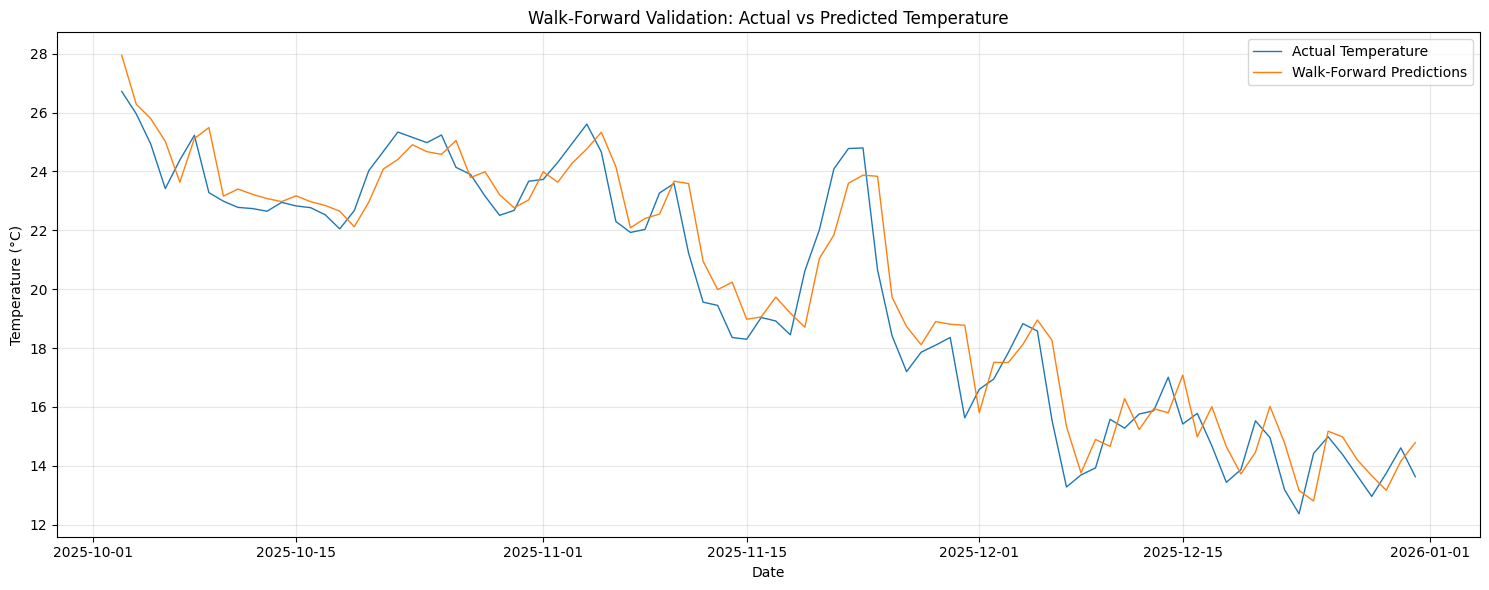

In [49]:
walk_forward_predictions_series = pd.Series(
    walk_forward_predictions,
    index=validation_test.index
)

plt.figure(figsize=(15, 6))

plt.plot(
    validation_test.index,
    validation_test,
    label="Actual Temperature",
    linewidth=1
)

plt.plot(
    walk_forward_predictions_series.index,
    walk_forward_predictions_series,
    label="Walk-Forward Predictions",
    linewidth=1
)

plt.title("Walk-Forward Validation: Actual vs Predicted Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 45. Final Model Performance Comparison

The ARIMA model was evaluated using two approaches:

- **Full Test-Period Forecasting:** Forecasts the entire 731-day test period without updating the model with actual test observations.
- **Walk-Forward Validation:** Forecasts one day at a time over the final 90 test observations, using the actual previous observations as history.

The two approaches cover different horizons, so their errors are not directly comparable. Section 45b evaluates the full forecast over the same 90 days.

In [50]:
final_comparison = pd.DataFrame({
    "Evaluation": [
        "Full Test-Period Forecast",
        "Walk-Forward Validation (90 days)"
    ],
    "MAE": [
        mean_absolute_error(test, forecast),
        walk_forward_mae
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(test, forecast)),
        walk_forward_rmse
    ],
    "MAPE (%)": [
        mean_absolute_percentage_error(test, forecast) * 100,
        walk_forward_mape
    ]
})

display(final_comparison.round(3))

,Evaluation,MAE,RMSE,MAPE (%)
0,Full Test-Period Forecast,17.164,18.964,72.212
1,Walk-Forward Validation (90 days),0.871,1.101,4.724


## 45b. Fair Comparison on the Same 90-Day Window

The walk-forward model uses actual observations as history, so each of its predictions is one-step-ahead. To compare fairly, we evaluate the full-horizon ARIMA forecast on the same 90 days.

In [51]:
full_last90 = forecast.loc[validation_test.index]

fair_mae = mean_absolute_error(validation_test, full_last90)
fair_rmse = np.sqrt(mean_squared_error(validation_test, full_last90))

fair_comparison = pd.DataFrame({
    "Evaluation": [
        "ARIMA full forecast (same 90 days)",
        "ARIMA walk-forward (90 days)"
    ],
    "MAE": [fair_mae, walk_forward_mae],
    "RMSE": [fair_rmse, walk_forward_rmse]
})

display(fair_comparison.round(3))

,Evaluation,MAE,RMSE
0,ARIMA full forecast (same 90 days),18.022,18.473
1,ARIMA walk-forward (90 days),0.871,1.101


## 46. SARIMAX Forecast with 95% Confidence Intervals

The SARIMAX model with Fourier terms was used to forecast Cairo's daily average temperature over the test period (2024–2025).

A 95% confidence interval was calculated for each forecast to represent the uncertainty around the predicted temperature.

The forecast is compared with the actual observed temperatures to evaluate how closely the model follows the annual seasonal pattern.

The confidence intervals provide a range of plausible values for the predicted temperature. Wider intervals indicate greater uncertainty in the forecast.


In [52]:
sarima_forecast_result = sarima_fitted.get_forecast(
    steps=len(test),
    exog=X_test_f
)

sarima_predictions_ci = sarima_forecast_result.predicted_mean
sarima_confidence_intervals = sarima_forecast_result.conf_int(alpha=0.05)

sarima_predictions_ci.index = test.index
sarima_confidence_intervals.index = test.index

display(pd.DataFrame({
    "Actual Temperature": test,
    "SARIMAX Forecast": sarima_predictions_ci,
    "Lower 95% CI": sarima_confidence_intervals.iloc[:, 0],
    "Upper 95% CI": sarima_confidence_intervals.iloc[:, 1]
}).head(10))

,Actual Temperature,SARIMAX Forecast,Lower 95% CI,Upper 95% CI
date,,,,
2024-01-01,14.91,14.374933,11.737630,17.012235
2024-01-02,15.59,13.701668,10.000800,17.402535
2024-01-03,14.39,13.239553,9.163179,17.315927
2024-01-04,14.18,12.917710,8.688996,17.146425
2024-01-05,13.86,12.689490,8.396455,16.982524
2024-01-06,15.40,12.524185,8.203583,16.844787
2024-01-07,14.60,12.401588,8.069097,16.734078
2024-01-08,13.45,12.308392,7.970761,16.646023
2024-01-09,10.95,12.235840,7.895984,16.575696


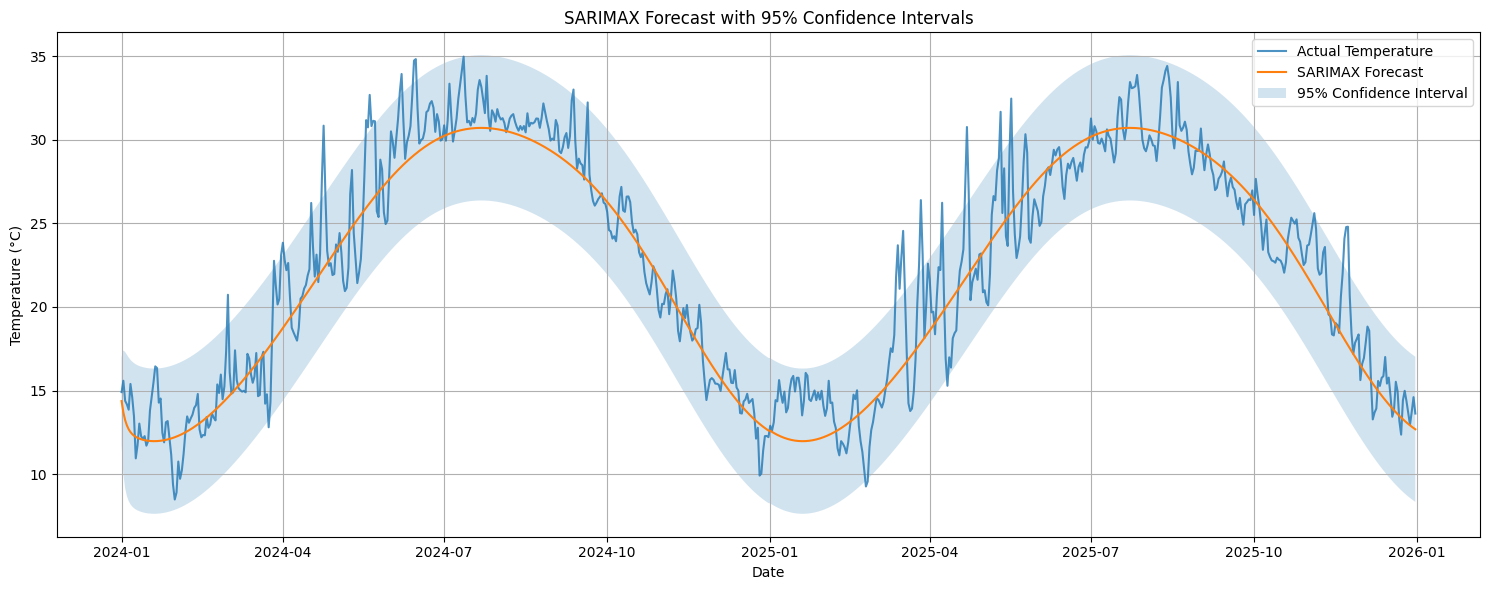

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))

plt.plot(test.index, test, label="Actual Temperature", alpha=0.8)
plt.plot(test.index, sarima_predictions_ci, label="SARIMAX Forecast")

plt.fill_between(
    test.index,
    sarima_confidence_intervals.iloc[:, 0],
    sarima_confidence_intervals.iloc[:, 1],
    alpha=0.2,
    label="95% Confidence Interval"
)

plt.title("SARIMAX Forecast with 95% Confidence Intervals")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

## 47. Final Conclusions

The time-series analysis shows a clear annual cycle in Cairo's daily average temperature. The series is stationary according to both ADF and KPSS, so d = 0 is supported, and the seasonal structure is handled through Fourier terms rather than through differencing.

On the 731-day test period (2024 to 2025), the models rank as follows:

* **SARIMAX(1, 0, 1) + Fourier (K=3):** MAE 1.6093 °C, RMSE 2.1624 °C. This is the best model.
* **Seasonal naive (t-365):** MAE 2.2851 °C, RMSE 2.9134 °C. The SARIMAX model reduces the MAE by about 30% compared with this baseline, so it adds value beyond a simple "same day last year" forecast.
* **ARIMA(4, 0, 2):** MAE 17.1639 °C, RMSE 18.9636 °C. The non-seasonal model reverts toward the mean and cannot follow the annual cycle over a two-year horizon.

The walk-forward validation gives an MAE of 0.87 °C, but it is one-step-ahead and uses actual observations as history. On the same 90 days, the full ARIMA forecast gives an MAE of 18.02 °C. The walk-forward result therefore reflects the forecasting setup, not a better model, and it should not be reported as the model's expected accuracy.

The Ljung-Box test rejects the null hypothesis for the ARIMA residuals (p < 0.05 at lags 10 and 20), while the SARIMAX residuals show no remaining autocorrelation at lag 1 (p = 0.82). The Jarque-Bera test rejects normality for both models, which is common in weather data, so the confidence intervals should be interpreted with that in mind.

Limitations: the analysis uses one city and one target variable. The Fourier terms assume that the annual cycle is stable from year to year, which may weaken under climate change. The test period is two years, and some ARIMA fits produced convergence warnings.